# Preprocessing: BPE tokenization

Dataset: `cardiffnlp/tweet_eval` (emotion), about 3.3k training tweets.

Preprocessing is kept minimal: punctuation is kept, and there is no stopword removal, stemming or lemmatisation (tweets are short, noisy and full of misspellings). We compare BPE tokenizers over a grid of hyperparameters:
- **`lowercase`** or keep the original case (capitals can signal intensity);
- **`vocab_size`**: number of tokens in the vocabulary;
- **`min_frequency`**: a pair of tokens is only merged if it appears at least this many times;
- **`pre-tokenizer`**: `Metaspace` (tutorial default) splits only on blanks and marks each word start with `▁`, so `sad!!` becomes the chunk `▁sad!!`. `Whitespace` also splits punctuation (`sad`, `!!`) but drops the blanks.

The tokenizer is trained with `part1.experiment.train_tokenizer` from the tutorial.

Before training, we check the training set for duplicate tweets. If the same tweet appears multiple times with the same label, we keep only one occurrence. If identical tweets have conflicting labels, an error is raised to avoid introducing contradictory training examples.

We also define the outcome space containing the emotion classes, which will be used by our classification models.

In [1]:
import sys
from pathlib import Path

# Assuming the working directory is root/part1
sys.path.insert(0, str(Path.cwd().parent))

import part1
from datasets import load_dataset

dataset = load_dataset("cardiffnlp/tweet_eval", "emotion")
seen = {}
unique_indices = []
for i, example in enumerate(dataset["train"]):
    text, label = example["text"], example["label"]
    if text in seen:
        if seen[text] != label:
            raise ValueError(f"Duplicate training text has conflicting labels at row {i}.")
    else:
        seen[text] = label
        unique_indices.append(i)
removed = len(dataset["train"]) - len(unique_indices)
dataset["train"] = dataset["train"].select(unique_indices)
print(f"Removed {removed} duplicate training examples; {len(dataset['train'])} remain.")
emotion_outcome_space = part1.clslib.NamedClasses(dataset["train"].features["label"].names)
example_tweet = dataset["train"][0]["text"]

print(dataset)
print(emotion_outcome_space)
print("Original:", example_tweet)

Removed 25 duplicate training examples; 3232 remain.
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3232
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
})
0: anger, 1: joy, 2: optimism, 3: sadness
Original: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry


## Byte-Pair Encoding Tokenizer

We use BPE to tokenize the tweets. BPE is a subword tokenization method that starts with smaller units and repeatedly merges frequent pairs to build a vocabulary.

This is useful for tweets because they often contain informal language, misspellings, and uncommon words. Rather than treating every word as a separate token, BPE can represent words using smaller subword units.

The BPEPreprocessor class handles optional lowercasing and tokenizer training. Its fit() method trains the tokenizer on the training texts, while tokenize() applies the learned tokenization to new text.

The tokenizer is trained only on the training data to prevent information from the validation or test sets from influencing the vocabulary.

In [2]:
from tokenizers.pre_tokenizers import Metaspace, Whitespace

PRETOKENIZERS = {"metaspace": Metaspace, "whitespace": Whitespace}


class BPEPreprocessor:
    """Optional lowercasing + BPE tokenization.

    Call `fit(train_texts)` first, then `tokenize(text)` returns the BPE tokens.
    """

    def __init__(self, lowercase=True, vocab_size=5000, min_frequency=2, pretokenizer="metaspace"):
        self.lowercase = lowercase
        self.vocab_size = vocab_size
        self.min_frequency = min_frequency
        self.pretokenizer = pretokenizer
        self.tokenizer = None

    def fit(self, train_texts):
        corpus = [t.lower() for t in train_texts] if self.lowercase else list(train_texts)
        self.tokenizer = part1.experiment.train_tokenizer(
            corpus, self.vocab_size, self.min_frequency, pretokenizer=PRETOKENIZERS[self.pretokenizer]()
        )
        return self

    def tokenize(self, text):
        return self.tokenizer.encode(text.lower() if self.lowercase else text).tokens

    def __len__(self):
        """Number of tokens in the learned vocabulary."""
        return self.tokenizer.get_vocab_size()

## Hyperparameter grid

To investigate how tokenization choices affect the representation of tweets, we train BPE tokenizers using different combinations of hyperparameters.

We vary whether text is lowercased, the vocabulary size, the minimum frequency required for token merges, and the pre-tokenization method (Metaspace or Whitespace).

Using itertools.product, we generate all 24 possible configurations and train a separate tokenizer for each one.

We then apply each tokenizer to the same example tweet to observe how the different configurations affect the resulting tokens.

In [3]:
import itertools
from tqdm.auto import tqdm

GRID = {
    "lowercase": [True, False],
    "vocab_size": [500, 1000, 2000],
    "min_frequency": [2, 5],
    "pretokenizer": ["metaspace", "whitespace"],
}
configs = [dict(zip(GRID, values)) for values in itertools.product(*GRID.values())]
print(len(configs), "configurations")

train_texts = dataset["train"]["text"]
preprocessors = [BPEPreprocessor(**cfg).fit(train_texts) for cfg in tqdm(configs)]

print("Original:", example_tweet)
for cfg, prep in zip(configs, preprocessors):
    print(cfg, "->", prep.tokenize(example_tweet))


def find(**wanted):
    """Return the fitted preprocessor matching the given hyperparameters."""
    return next(p for c, p in zip(configs, preprocessors) if all(c[k] == v for k, v in wanted.items()))

24 configurations


  0%|          | 0/24 [00:00<?, ?it/s]









































































Original: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'metaspace'} -> ['▁', '“', 'w', 'or', 'ry', '▁is', '▁a', '▁d', 'ow', 'n', '▁p', 'ay', 'm', 'ent', '▁on', '▁a', '▁p', 'ro', 'ble', 'm', '▁you', '▁m', 'ay', '▁ne', 'ver', '▁have', "'", '.', '▁', '\xa0', 'j', 'o', 'y', 'ce', '▁me', 'y', 'er', '.', '▁', '▁#', 'm', 'ot', 'i', 'v', 'at', 'ion', '▁#', 'le', 'ad', 'ers', 'h', 'i', 'p', '▁#', 'w', 'or', 'ry']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'whitespace'} -> ['“', 'wor', 'ry', 'is', 'a', 'do', 'wn', 'p', 'ay', 'm', 'ent', 'on', 'a', 'pro', 'ble', 'm', 'you', 'm', 'ay', 'ne', 'ver', 'have', "'", '.', 'jo', 'y', 'ce', 'me', 'y', 'er', '.', '#', 'mo', 'ti', 'v', 'ation', '#', 'le', 'ad', 'ers', 'hi', 'p', '#', 'wor', 'ry']
{'lowercase': True, 'vocab

## Inspecting every vocabulary

We inspect the vocabulary learned by each BPE configuration to better understand the effect of the tokenizer hyperparameters.

For each vocabulary, we calculate the mean, median, and maximum token lengths. We also examine the longest tokens and tokens containing punctuation or other special symbols.

These observations help us understand whether a tokenizer tends to produce shorter subword units or longer tokens, and how well it handles the informal language commonly found in tweets.

- **longest tokens**: whole words, hashtags or emojis it managed to keep in one piece;
- **first learned tokens**: ids right after the initial alphabet are the earliest (most frequent) merges;
- **tokens with symbols**: how punctuation and hashtags are handled.

In [4]:
import statistics

clean = lambda t: t.lstrip("\u2581")  # drop the Metaspace marker when measuring length

for cfg, prep in zip(configs, preprocessors):
    vocab = prep.tokenizer.get_vocab()  # token -> id
    by_id = sorted(vocab, key=vocab.get)

    print("=" * 100)
    print(cfg)
    lengths = [len(clean(t)) for t in vocab]
    print(f"token length: mean={statistics.mean(lengths):.2f}  median={statistics.median(lengths)}  max={max(lengths)}")
    print("longest tokens:", sorted(vocab, key=lambda t: -len(clean(t)))[:25])
    print("tokens with symbols:", [t for t in by_id if len(clean(t)) > 1 and not clean(t).replace("'", "").isalnum()][:30])

{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'metaspace'}
token length: mean=1.54  median=1.0  max=5
longest tokens: ['[UNK]', "▁don't", '▁@user', '▁about', 'user', "▁it's", 'ight', '▁just', 'ally', 'ress', '▁have', '▁this', 'king', '▁that', '▁some', '▁they', '▁when', '▁your', '▁with', '▁like', 'ould', '▁what', '▁was', '▁don', 'amp']
tokens with symbols: ['[UNK]', '▁@user', '..', '▁#s', '\\n', '!!', '...', '▁#b', '▁#h', '▁#f', '▁#d']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'whitespace'}
token length: mean=1.67  median=1.0  max=6
longest tokens: ['people', 'cking', 'about', 'thing', 'press', 'ation', '[UNK]', 'some', 'ever', 'just', 'tion', 'that', 'pres', 'ight', 'ther', 'from', 'your', 'peop', 'with', 'have', 'user', 'this', 'king', 'ally', 'ould']
tokens with symbols: ['[UNK]', '..', '!!', '...']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 5, 'pretokenizer': 'metaspace'}
token length: mean=1.54  median=1.0  

## Default tokenizer

For the following experiments, we use a default BPE configuration with lowercasing enabled, a vocabulary size of 2000, a minimum frequency of 2, and the Whitespace pre-tokenizer.

We fit this tokenizer on the training texts and then use it to tokenize the training, validation, and test splits.

Using the same fitted tokenizer across all splits ensures that every tweet is represented using a consistent vocabulary.

Shared configuration to start from: lowercase, `Whitespace` pre-tokenizer, 2000 tokens, `min_frequency=2`. Use `default_prep` to tokenize new text, and `preprocessed` (train/validation/test) for the already tokenized dataset with its labels.

In [5]:
default_prep = BPEPreprocessor(lowercase=True, vocab_size=2000, min_frequency=2, pretokenizer="whitespace").fit(train_texts)

# Whole dataset, preprocessed: tokens and labels per split (same fitted tokenizer for all splits)
preprocessed = {
    split: {
        "tokens": [default_prep.tokenize(t) for t in dataset[split]["text"]],
        "labels": dataset[split]["label"],
    }
    for split in dataset
}
print({split: len(d["tokens"]) for split, d in preprocessed.items()})
print(preprocessed["train"]["tokens"][0], preprocessed["train"]["labels"][0])




{'train': 3232, 'test': 1421, 'validation': 374}
['“', 'worry', 'is', 'a', 'down', 'pay', 'ment', 'on', 'a', 'problem', 'you', 'may', 'never', 'have', "'", '.', 'joy', 'ce', 'me', 'y', 'er', '.', '#', 'motiv', 'ation', '#', 'leaders', 'hip', '#', 'worry'] 2


# Model Architectures

This notebook contains the implementations of the three text classification architectures used in our first project:

1. Log-linear softmax classifier

2. Single-hidden-layer Multilayer Perceptron (MLP)

3. Two-hidden-layer Multilayer Perceptron (MLP)


In [6]:
import scipy
from scipy.special import softmax
import numpy as np
from tokenizers import Tokenizer

Base Classes

We define two base classes to provide a common structure for our text representations and classification models.

The Encoder class defines the interface for transforming a text into a numerical feature vector. Its __len__() method returns the dimensionality of the representation, while __call__() converts a text into its vector representation.

The ProbabilisticModel class defines an interface for classifiers that return a probability distribution over the possible emotion classes.

These base classes help maintain a consistent structure across different encoders and models.

In [7]:
class Encoder:
    """Base class for text feature encoders."""

    def __len__(self):
        raise NotImplementedError

    def __call__(self, x: str) -> np.ndarray:
        raise NotImplementedError


class ProbabilisticModel:
    """Base class for probabilistic classifiers."""

    def __call__(self, x: str) -> np.ndarray:
        raise NotImplementedError

**1. Log-Linear Softmax Classifier**

The log-linear softmax classifier is a linear classification model that predicts the probability of each emotion class from a numerical representation of a tweet.

First, the encoder converts the input text into a feature vector (h) of dimension (D). The model then calculates a score for each of the (K) possible classes using a weight matrix (W) and bias vector (b).

The output contains one probability for each emotion class, and all probabilities sum to 1.

Because the model uses a linear transformation without hidden layers, it provides a baseline for comparison with the more complex neural network architectures.

In [8]:
class LogLinearSoftmaxRegressor(ProbabilisticModel):

    def __init__(self, encoder, W: 'np.array', b: 'np.array'):
        """
        encoder: turns a text (str) into a D-dimensional vector
        W: KxD matrix of weights
        b: B-dimensional vector of weights
        """
        self.encoder = encoder
        assert W.shape[0] == len(b), f"The matrix W should have shape KxD with K={len(b)}"
        assert W.shape[1] == len(encoder), f"The matrix W should have shape KxD with D={len(encoder)}"
        self.W = W
        self.b = b
        
    def __call__(self, x: str) -> 'np.array':
        h = self.encoder(x) # D features
        s = np.dot(self.W, h) + self.b # K linear predictors
        pmf = softmax(s) # K probabilities
        return pmf

**2. Single-Hidden-Layer MLP**

The single-hidden-layer MLP is a neural network that introduces a hidden layer between the input representation and the output classes.

Unlike the log-linear classifier, the MLP applies a nonlinear activation function, allowing it to learn more complex patterns in the input features.

We use the SparseMLP implementation provided in the tutorial. The single-hidden-layer MLP allows us to investigate whether adding nonlinearity improves emotion classification compared with the linear baseline

In [9]:
from part1.smlp import SparseMLP

**3. Two-hidden-layer Multilayer Perceptron (MLP)**

We extend the tutorial's SparseMLP architecture by adding a second hidden layer.

The additional layer consists of a linear transformation followed by a ReLU activation and dropout. This allows the network to learn more complex relationships between input features before predicting the emotion class.

The model is trained using negative log-likelihood loss (NLLLoss) and the AdamW optimizer. Dropout and weight decay are used to reduce overfitting.

During training, we evaluate the model on the validation set after each epoch and calculate the macro-F1 score. The model with the highest validation macro-F1 is saved and restored after training.

This architecture allows us to examine whether increasing network depth improves emotion classification performance.

In [10]:
import json
import torch
import torch.nn as nn
from scipy.sparse import csr_matrix
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from part1.smlp import SparseMLP, SparseDataset, sparse_collate, train_one_epoch, evaluate


class MLPClassifier(SparseMLP):
    """Tutorial MLP with one additional hidden layer."""

    def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.1):
        super().__init__(input_dim, hidden_dim, num_classes, dropout)
        self.model_args = {"input_dim": input_dim, "hidden_dim": hidden_dim,
                           "num_classes": num_classes, "dropout": dropout}
        self.output = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes), nn.LogSoftmax(dim=-1)
        )

    def fit(self, train_X, train_y, val_X, val_y, save_to, batch_size=64,
            learning_rate=1e-4, weight_decay=1e-4, num_epochs=20, device="cpu"):
        """Train with NLL loss and keep the best validation macro-F1 model."""
        if num_epochs < 1:
            raise ValueError("num_epochs must be at least 1")
        train_loader = DataLoader(SparseDataset(train_X, train_y), batch_size=batch_size,
                                  shuffle=True, collate_fn=sparse_collate)
        val_loader = DataLoader(SparseDataset(val_X, val_y), batch_size=batch_size,
                                shuffle=False, collate_fn=sparse_collate)

        with open(f"{save_to}.json", "w", encoding="utf-8") as f:
            json.dump(self.model_args, f, indent=2)
        self.to(device)
        criterion = nn.NLLLoss()
        optimizer = torch.optim.AdamW(self.parameters(), lr=learning_rate, weight_decay=weight_decay)

        best_loss = float("inf")
        print("Training...")
        for epoch in tqdm(range(num_epochs)):
            train_metrics = train_one_epoch(self, train_loader, optimizer, criterion, device)
            val_metrics, preds = evaluate(self, val_loader, criterion, device)
            val_f1 = f1_score(val_y, preds, labels=range(self.model_args["num_classes"]),
                              average="macro", zero_division=0)
            print(f"Epoch {epoch + 1:02d} | train loss: {train_metrics['loss']:.4f} | "
                  f"val loss: {val_metrics['loss']:.4f} | val macro-F1: {val_f1:.4f}")
            if val_metrics["loss"] <= best_loss:
                best_loss = val_metrics["loss"]
                best_f1 = val_f1
                best_epoch, predictions = epoch, preds
                torch.save(self.state_dict(), f"{save_to}.pt")
        self.load_state_dict(torch.load(f"{save_to}.pt", map_location=device, weights_only=True))
        return best_epoch, best_f1, predictions

    @classmethod
    def load(cls, path):
        with open(f"{path}.json", encoding="utf-8") as f:
            model = cls(**json.load(f))
        model.load_state_dict(torch.load(f"{path}.pt", map_location="cpu", weights_only=True))
        return model

# Representation Spaces

1. Token Indicators
2. Bag of Words
3. TF-IDF

1. Token Indicators

The token indicator representation converts each tweet into a binary feature vector based on the BPE vocabulary.

Each position in the vector corresponds to one token in the vocabulary. A value of 1 indicates that the token occurs in the tweet, while a value of 0 indicates that it does not.

This representation captures the presence or absence of tokens but ignores their frequency and order.

In [11]:
import numpy as np

class BPETokenIndicator(part1.clslib.Encoder):
    """Encode preprocessed BPE tokens as a binary indicator vector."""

    def __init__(self, prep):
        self.prep = prep
        self.vocab = prep.tokenizer.get_vocab()

    def __len__(self):
        return self.prep.tokenizer.get_vocab_size()

    def __call__(self, text):
        tokens = self.prep.tokenize(text)
        ids = [self.vocab[token] for token in set(tokens)]
        vector = np.zeros(len(self))
        vector[ids] = 1
        return vector


encoder = BPETokenIndicator(default_prep)
h = encoder(dataset["train"]["text"][0])
id_to_token = {i: t for t, i in default_prep.tokenizer.get_vocab().items()}
print("dimensions:", len(encoder), "| active:", int(h.sum()))
print(sorted(id_to_token[i] for i in np.flatnonzero(h)))

dimensions: 2000 | active: 25
['#', "'", '.', 'a', 'ation', 'ce', 'down', 'er', 'have', 'hip', 'is', 'joy', 'leaders', 'may', 'me', 'ment', 'motiv', 'never', 'on', 'pay', 'problem', 'worry', 'y', 'you', '“']


2. Bag of Words(BoW)

Bag-of-Words is a method for converting text into numerical feature vectors. It represents each text by counting how often each token appears, without considering the order in which the tokens occur. 

In our project, we use a trained Byte-Pair Encoding (BPE) tokenizer to split tweets into tokens, which may include complete words, subwords, and punctuation. Each tweet is represented by a fixed-length vector, where each position corresponds to a token in the vocabulary and its value indicates how frequently that token occurs in the tweet.

In [12]:
class BagOfWords(Encoder):

    def __init__(self, preprocessor: BPEPreprocessor):
        self.prep = preprocessor
        self.tokenizer = preprocessor.tokenizer
        self._dim = self.tokenizer.get_vocab_size()

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return self._dim

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a vector counting each token's occurrences"""
        text = x.lower() if self.prep.lowercase else x
        token_ids = self.tokenizer.encode(text).ids
        vector = np.zeros(len(self))
        np.add.at(vector, token_ids, 1)
        return vector

3. TF-IDF 

TF-IDF is a text representation that combines token frequency with a measure of how common each token is across the training documents.

Unlike Bag-of-Words, which uses only raw token counts, TF-IDF gives relatively higher weight to tokens that appear frequently in a particular tweet but are less common across the dataset.

The TfIdf class calculates document frequencies using the training texts and stores the resulting IDF weights.

When encoding a new tweet, it counts the BPE token occurrences and multiplies these counts by the learned IDF values.

This representation allows us to investigate whether weighting tokens by their importance across the dataset improves emotion classification.

In [13]:
from tokenizers import Tokenizer
from typing import List

class TfIdf(part1.clslib.Encoder):
    def __init__(self, preprocessor: BPEPreprocessor, training_texts: List[str]) -> None:
        self.preprocessor = preprocessor
        self.tokeniser = preprocessor.tokenizer
        document_frequency = np.zeros(len(self))
        for text in training_texts:
            text = text.lower() if self.preprocessor.lowercase else text
            token_ids = self.tokeniser.encode(text).ids
            document_frequency[list(set(token_ids))] += 1
        self.idf = np.log((1 + len(training_texts)) / (1 + document_frequency)) + 1

    def __len__(self) -> int:
        return self.tokeniser.get_vocab_size()

    def __call__(self, text: str) -> np.ndarray:
        text = text.lower() if self.preprocessor.lowercase else text
        token_ids = self.tokeniser.encode(text.lower()).ids
        return np.bincount(token_ids, minlength = len(self)) * self.idf

# Experiments

**Cross-validation setup**

We compare three text representation methods (Token Indicators, Bag-of-Words, and TF-IDF) with three classification architectures (Log-Linear Softmax, Single-Hidden-Layer MLP, and Two-Hidden-Layer MLP).

This results in nine different model configurations.

To evaluate these models, we use 5-fold cross-validation on the training dataset with a fixed random seed of 0. Each fold provides a different training and validation split.

We use macro-F1 as our main evaluation metric. Macro-F1 calculates the F1 score separately for each emotion class and then takes their unweighted average. This gives equal importance to every class, regardless of how many examples it contains.

**Training Functions**

We define helper functions to train and evaluate the different model architectures.

The run_single_layer_mlp() function uses the tutorial's cross-validation experiment framework to train either a log-linear classifier or a single-hidden-layer MLP, depending on the selected model option.

The run_two_layer_mlp() function constructs sparse feature matrices, creates the two-hidden-layer model, and trains it using the specified training and validation indices.

For the two-hidden-layer MLP, we save the model configuration, the best epoch, and the best validation macro-F1 score.

These functions provide a consistent way to evaluate the architectures using the selected text representations.


In [14]:
seed = 0
num_folds = 5
train_pairs = list(zip(dataset["train"]["text"], dataset["train"]["label"]))
folds = part1.experiment.cross_validation_split(train_pairs, k = num_folds, seed = seed)
results_folder = Path(part1.__file__).resolve().parent.parent / "results"

mlp_arguments = {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
                 "learning_rate": 3e-4, "weight_decay": 1e-4, "num_epochs": 20}

encoders = {
    "indicator": lambda texts: BPETokenIndicator(default_prep),
    "bow": lambda texts: BagOfWords(default_prep),
    "tfidf": lambda texts: TfIdf(default_prep, texts)
}

def run_single_layer_mlp(encoder, fold, split, model_name, model_option):
    results = part1.experiment.cross_validation_experiment(
        data_splits = {fold: split}, outcome_space = emotion_outcome_space,
        encoder = encoder, model_option = model_option,
        save_to = f"../results/{model_name}", smlp_args = mlp_arguments)
    labels = [label for _, label in split["validation"]]
    return f1_score(y_true = labels, y_pred = results["predictions"][fold], average = "macro")

def run_two_layer_mlp(encoder, fold, split, model_name):
    train_X = csr_matrix([encoder(text) for text in train_texts])
    train_y = np.asarray(preprocessed["train"]["labels"], dtype=int)
    model_folder = results_folder / model_name / f"seed-{seed}"

    print(f"\n{model_name} | seed {seed} | fold {fold + 1}/{num_folds}")
    fold_folder = model_folder / f"fold-{fold}"
    fold_folder.mkdir(parents=True, exist_ok=True)

    train_ids = np.asarray(split["training_ids"], dtype=int)
    val_ids = np.asarray(split["validation_ids"], dtype=int)
    torch.manual_seed(seed)
    model = MLPClassifier(train_X.shape[1], mlp_arguments["hidden_dim"],
                          len(emotion_outcome_space), mlp_arguments["dropout"])
    best_epoch, best_f1, _ = model.fit(
        train_X[train_ids], train_y[train_ids], train_X[val_ids], train_y[val_ids],
        save_to=str(fold_folder / "model"), batch_size=mlp_arguments["batch_size"],
        learning_rate=mlp_arguments["learning_rate"], weight_decay=mlp_arguments["weight_decay"],
        num_epochs=mlp_arguments["num_epochs"]
    )
    with open(fold_folder / "metrics.json", "w", encoding="utf-8") as f:
        json.dump({"model_args": mlp_arguments, "best_epoch": best_epoch,
                   "macro_f1": best_f1}, f, indent=2)
    return best_f1


**Comparing model configurations**

We evaluate every combination of text representation and classification architecture across the five cross-validation folds.

For each combination, we create the corresponding encoder, train the selected classifier, and record its validation macro-F1 score.

After all experiments, we collect the scores in a DataFrame and save them to a CSV file.

We also calculate the mean, standard deviation, and number of fold scores for each model, and visualize the results using boxplots.

These results allow us to compare how the choice of representation and model architecture affects emotion classification performance.

  0%|          | 0/1 [00:00<?, ?it/s]

/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.

  0%|          | 0/1 [00:00<?, ?it/s]

/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  0%|          | 0/1 [00:00<?, ?it/s]

/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.

... (112 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3023 | val loss: 1.2456 | val macro-F1: 0.1538
Epoch 02 | train loss: 1.1838 | val loss: 1.1932 | val macro-F1: 0.1827
Epoch 03 | train loss: 1.0343 | val loss: 1.0979 | val macro-F1: 0.3910
Epoch 04 | train loss: 0.7833 | val loss: 0.9977 | val macro-F1: 0.4686
Epoch 05 | train loss: 0.5085 | val loss: 0.9552 | val macro-F1: 0.5416
Epoch 06 | train loss: 0.3084 | val loss: 0.9586 | val macro-F1: 0.5641
Epoch 07 | train loss: 0.1886 | val loss: 1.0154 | val macro-F1: 0.5874
Epoch 08 | train loss: 0.1290 | val loss: 1.0877 | val macro-F1: 0.5773
Epoch 09 | train loss: 0.0901 | val loss: 1.1563 | val macro-F1: 0.5760
Epoch 10 | train loss: 0.0700 | val loss: 1.2113 | val macro-F1: 0.5871
Epoch 11 | train loss: 0.0553 | val loss: 1.2660 | val macro-F1: 0.5749
Epoch 12 | train loss: 0.0434 | val loss: 1.3290 | val macro-F1: 0.5900
Epoch 13 | train loss: 0.0395 | val loss: 1.3427 | val macro-F1: 0.5827
Epoch 14 | train loss: 0.0366 | val loss: 1.3951 | val macro-F1:

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3068 | val loss: 1.2343 | val macro-F1: 0.1532
Epoch 02 | train loss: 1.1890 | val loss: 1.1788 | val macro-F1: 0.1997
Epoch 03 | train loss: 1.0390 | val loss: 1.0800 | val macro-F1: 0.3558
Epoch 04 | train loss: 0.7894 | val loss: 0.9653 | val macro-F1: 0.4989
Epoch 05 | train loss: 0.5096 | val loss: 0.9197 | val macro-F1: 0.5754
Epoch 06 | train loss: 0.3128 | val loss: 0.9409 | val macro-F1: 0.6129
Epoch 07 | train loss: 0.1922 | val loss: 0.9944 | val macro-F1: 0.6039
Epoch 08 | train loss: 0.1318 | val loss: 1.0623 | val macro-F1: 0.6129
Epoch 09 | train loss: 0.0919 | val loss: 1.1321 | val macro-F1: 0.6107
Epoch 10 | train loss: 0.0741 | val loss: 1.1680 | val macro-F1: 0.6035
Epoch 11 | train loss: 0.0549 | val loss: 1.2304 | val macro-F1: 0.6042
Epoch 12 | train loss: 0.0478 | val loss: 1.2738 | val macro-F1: 0.6054
Epoch 13 | train loss: 0.0389 | val loss: 1.3177 | val macro-F1: 0.6135
Epoch 14 | train loss: 0.0357 | val loss: 1.3772 | val macro-F1:

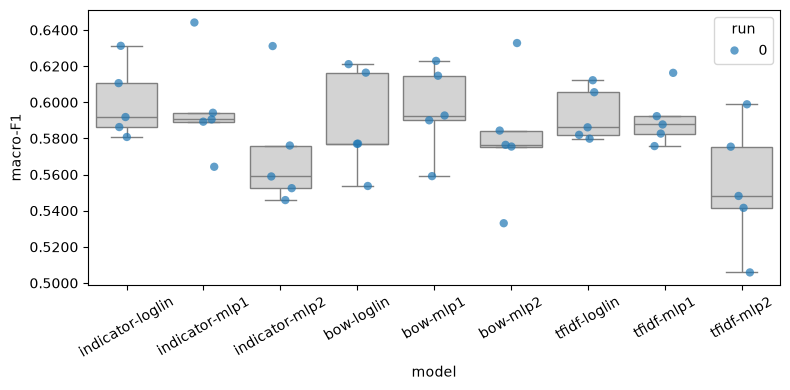

In [15]:
my_classifiers = {}
for encoder_name, make_encoder in encoders.items():
    for architecture in ["loglin", "mlp1", "mlp2"]:
        model_name = f"{encoder_name}-{architecture}"
        fold_scores = {}
        for fold, split in folds.items():
            torch.manual_seed(seed)
            encoder = make_encoder([text for text, _ in split["training"]])
            if architecture == "loglin":
                fold_scores[fold] = run_single_layer_mlp(encoder, fold, split, model_name, "logistic")
            elif architecture == "mlp1":
                fold_scores[fold] = run_single_layer_mlp(encoder, fold, split, model_name, "mlp")
            else:
                fold_scores[fold] = run_two_layer_mlp(encoder, fold, split, model_name)
        my_classifiers[model_name] = [{"accuracies": fold_scores}]

comparison = part1.analysis.make_data_frame(my_classifiers).rename(columns = {"accuracy": "macro-F1"})
comparison.to_csv(results_folder / "comparison.csv", index = False)
summary = comparison.groupby(by = "model", sort = False)["macro-F1"].agg(func = ["mean", "std", "count"])
print(summary.to_string())
part1.analysis.plot_box_and_points(df = comparison, metric = "macro-F1")

**Statistical comparison**

In addition to comparing average macro-F1 scores, we use the Bayesian correlated t-test implemented in the tutorial to compare model performance.

This method uses the cross-validation results to estimate the probabilities that one model outperforms another, that their performances are practically equivalent, or that the second model performs better.

We define a Region of Practical Equivalence (ROPE) of 0.005. Differences within this region are treated as practically equivalent.

The compare_all_pairs() function performs pairwise comparisons between all model configurations and reports the estimated probabilities together with an effect size.

This analysis helps us assess whether observed differences in performance are meaningful rather than relying only on mean scores.

In [16]:
from itertools import combinations

rope_size = 0.005


def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data["accuracies"].values()) for run_data in data[sys_name]])


def compare_all_pairs(classifiers, rope_size=0.005, plot=True):
    for name_a, name_b in combinations(classifiers.keys(), 2):
        posterior = part1.analysis.BenavoliCorrelatedT(
            get_all_measurements_for(classifiers, name_a).flatten(),
            get_all_measurements_for(classifiers, name_b).flatten(),
            names=[name_a, name_b],
        )
        p_a, p_tie, p_b = posterior.probs(rope_size)
        print(f"A={name_a} B={name_b}: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} "
              f"P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
        if plot:
            _ = posterior.plot(rope_size)


compare_all_pairs(my_classifiers, rope_size = rope_size, plot = False)


A=indicator-loglin B=indicator-mlp1: P(A wins)=0.4470 P(Tie)=0.3481 P(B wins)=0.2049 Effect Size=-0.39
A=indicator-loglin B=indicator-mlp2: P(A wins)=0.9023 P(Tie)=0.0539 P(B wins)=0.0438 Effect Size=-1.90
A=indicator-loglin B=bow-loglin: P(A wins)=0.7573 P(Tie)=0.1864 P(B wins)=0.0562 Effect Size=-1.40
A=indicator-loglin B=bow-mlp1: P(A wins)=0.4794 P(Tie)=0.2581 P(B wins)=0.2626 Effect Size=-0.32
A=indicator-loglin B=bow-mlp2: P(A wins)=0.8253 P(Tie)=0.0997 P(B wins)=0.0751 Effect Size=-1.42
A=indicator-loglin B=tfidf-loglin: P(A wins)=0.5974 P(Tie)=0.3078 P(B wins)=0.0949 Effect Size=-0.92
A=indicator-loglin B=tfidf-mlp1: P(A wins)=0.6390 P(Tie)=0.2279 P(B wins)=0.1331 Effect Size=-0.84
A=indicator-loglin B=tfidf-mlp2: P(A wins)=0.9641 P(Tie)=0.0164 P(B wins)=0.0195 Effect Size=-2.73
A=indicator-mlp1 B=indicator-mlp2: P(A wins)=0.9533 P(Tie)=0.0327 P(B wins)=0.0140 Effect Size=-2.78
A=indicator-mlp1 B=bow-loglin: P(A wins)=0.5701 P(Tie)=0.2349 P(B wins)=0.1950 Effect Size=-0.58
A=in

**Pairwise Model Comparisons**

We further investigate selected model configurations using the Bayesian correlated t-test.

For each pair, we compare their cross-validation macro-F1 scores and visualize the posterior distribution of the performance difference.

We focus on comparisons between different neural network depths, representation methods, and linear versus nonlinear classifiers.

These comparisons help us determine whether changes in the model architecture or text representation lead to meaningful improvements in emotion classification.

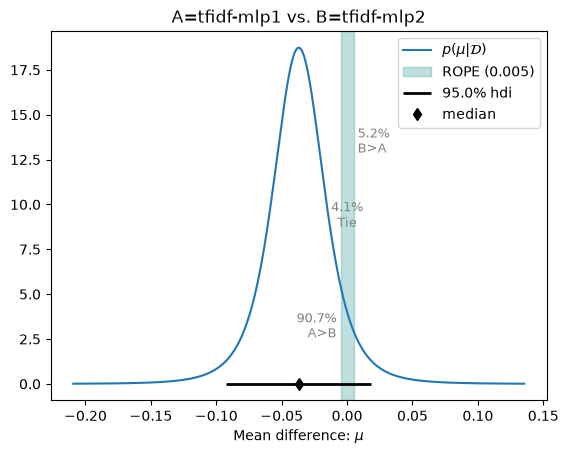

In [17]:
model_a, model_b = "tfidf-mlp1", "tfidf-mlp2"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)

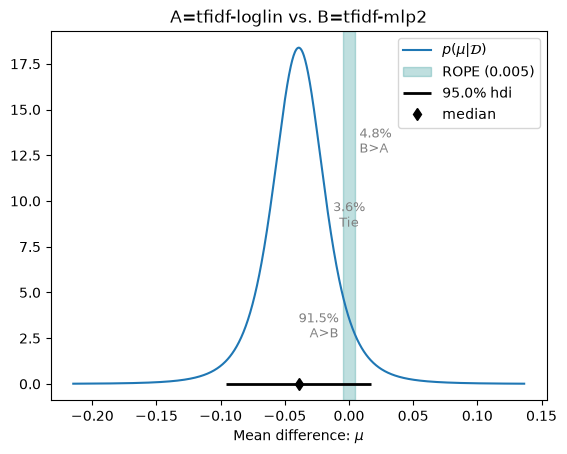

In [18]:
model_a, model_b = "tfidf-loglin", "tfidf-mlp2"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)

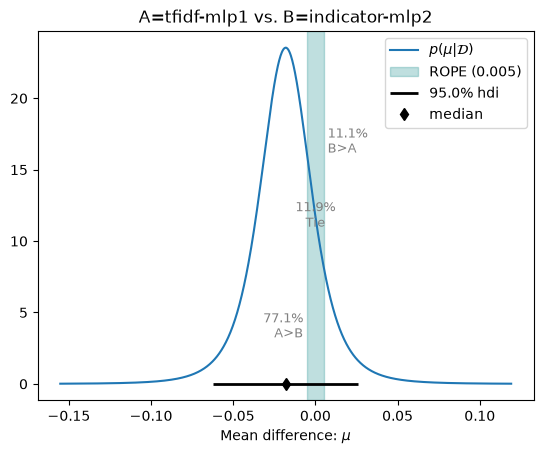

In [19]:
model_a, model_b = "tfidf-mlp1", "indicator-mlp2"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)

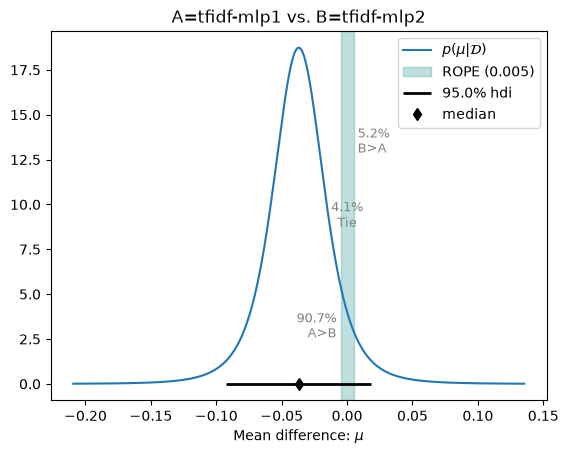

In [20]:
model_a, model_b = "tfidf-mlp1", "tfidf-mlp2"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)

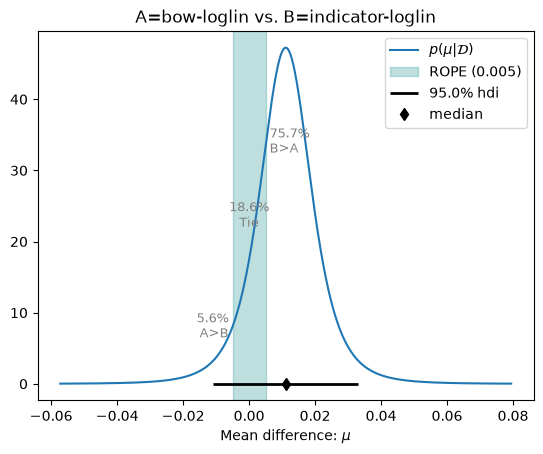

In [21]:
model_a, model_b = "bow-loglin", "indicator-loglin"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)